# Clases latentes de participación

Análisis de clases latentes (LCA), la metodología clásica en ciencia política para tipologias de
votantes (habitual, intermitente, solo presidenciales, abstencionista). Cada elección se convierte
en un indicador categorico (participación baja, media o alta frente al resto del pais) y el modelo
estima clases con un patrón típico de respuesta.

Ventajas frente a KMeans:
- Pertenencia probabilística: cada celda tiene una probabilidad por clase, lo que permite
  identificar celdas ambiguas (buen blanco de campaña).
- Selección de k con criterios de información (BIC, AIC) y entropía de clasificación.

Limitación: la unidad es la celda (sección x sexo x grupo de edad), no la persona. Las clases
describen grupos de ciudadanos, no individuos.

Tiempo estimado: ~2 min (el EM corre sobre patrones unicos, no sobre celdas).

## 1. Configuración

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

`INCLUIR_PJ` agrega la elección judicial 2025 como septimo indicador. `K_ELEGIDO = None` elige
el número de clases automáticamente (ver sección 5).

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

INCLUIR_PJ = False
N_CATEGORIAS = 3
ETIQUETAS_CAT = ["baja", "media", "alta"]

K_RANGO = range(2, 9)
K_VALIDO = range(4, 7)  # convocatoria pide 4-6 perfiles
K_ELEGIDO = None
MIN_PCT_CLASE = 5.0
UMBRAL_CLARA = 0.8

N_INIT = 20
MAX_ITER = 1000
TOL = 1e-8
N_BOOT = 5
N_EVAL = 10_000
RANDOM_STATE = 42

COLORES_PERFIL = ["#3288bd", "#66c2a5", "#fee08b", "#fdae61", "#f46d43", "#d53e4f",
                  "#9e0142", "#5e4fa2"]

## 3. Carga de datos

Celdas del notebook 03 con peso = SV + NV de 2024. Se conservan las celdas sin tasa PJ 2025
(Campeche no tiene datos de la elección judicial); solo se excluyen si `INCLUIR_PJ`.

In [3]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso"])
    .reset_index(drop=True)
)
del pesos, secciones
if INCLUIR_PJ:
    celdas = celdas.dropna(subset=["P_PJ2025"]).reset_index(drop=True)

celdas["MUJER"] = (celdas["SEXO"] == 1).astype(float)
celdas["RURAL_MIXTA"] = (celdas["TIPOSEC"].astype(str) != "U").astype(float)
w = celdas["peso"].to_numpy(dtype=float)
idx_eval = np.random.default_rng(RANDOM_STATE).choice(len(celdas), size=N_EVAL, replace=False, p=w / w.sum())
print(f"Celdas: {len(celdas):,}  peso: {w.sum():,.0f}")

Celdas: 657,497  peso: 71,203,577


## 4. Indicadores categoricos

### 4.1 Terciles ponderados por elección

Cada elección se corta en terciles ponderados por personas: baja, media y alta. Al ser relativos a
cada elección, eliminan el efecto común de presidenciales contra intermedias. Lo que queda es la
posición de cada celda frente al resto del pais en cada elección: una celda que es "alta" solo en
presidenciales aparece como un patrón distinto de una que es "alta" siempre.

In [4]:
def terciles_ponderados(x, w, n=N_CATEGORIAS):
    orden = np.argsort(x)
    acum = np.cumsum(w[orden]) / w.sum()
    cortes = np.interp(np.arange(1, n) / n, acum, x[orden])
    return np.searchsorted(cortes, x, side="right")


INDICADORES = ELECCIONES + (["P_PJ2025"] if INCLUIR_PJ else [])
cat = np.column_stack([terciles_ponderados(celdas[c].to_numpy(dtype=float), w) for c in INDICADORES])

pd.DataFrame(
    {c: np.bincount(cat[:, j], weights=w, minlength=N_CATEGORIAS) / w.sum() * 100
     for j, c in enumerate(INDICADORES)},
    index=ETIQUETAS_CAT,
).round(1)

,P2009,P2012,P2015,P2018,P2021,P2024
baja,33.3,33.3,33.3,33.2,33.3,33.3
media,33.3,33.4,33.4,33.4,33.3,33.4
alta,33.4,33.3,33.3,33.3,33.3,33.3


### 4.2 Patrones de respuesta

El modelo solo depende del patrón (la combinacion de categorias en las elecciones), así que las
celdas se colapsan a patrones con su peso total. El peso se normaliza para sumar el número de
celdas: las proporciones representan personas y el BIC usa n = celdas.

In [5]:
patrones, inv = np.unique(cat, axis=0, return_inverse=True)
inv = inv.ravel()
n_celdas = len(celdas)
J, C = len(INDICADORES), N_CATEGORIAS

w_pat = np.bincount(inv, weights=w)
f_pat = w_pat / w_pat.sum() * n_celdas

onehot = np.zeros((len(patrones), J * C))
onehot[np.arange(len(patrones))[:, None], np.arange(J) * C + patrones] = 1

print(f"Patrones observados: {len(patrones):,} de {C ** J:,} posibles")
top = pd.DataFrame(patrones, columns=INDICADORES).replace(dict(enumerate(ETIQUETAS_CAT)))
top["pct_personas"] = w_pat / w_pat.sum() * 100
top.sort_values("pct_personas", ascending=False).head(10).round(2)

Patrones observados: 728 de 729 posibles


,P2009,P2012,P2015,P2018,P2021,P2024,pct_personas
0,baja,baja,baja,baja,baja,baja,12.31
727,alta,alta,alta,alta,alta,alta,11.33
243,media,baja,baja,baja,baja,baja,2.33
485,media,alta,alta,alta,alta,alta,2.06
364,media,media,media,media,media,media,2.02
270,media,baja,media,baja,baja,baja,1.55
700,alta,alta,media,alta,alta,alta,1.55
27,baja,baja,media,baja,baja,baja,1.43
458,media,alta,media,alta,alta,alta,1.36
726,alta,alta,alta,alta,alta,media,1.18


## 5. Modelo

### 5.1 EM para clases latentes

Cada clase k tiene una proporción `pi_k` y, para cada indicador j, una distribución
`theta_kj` sobre las categorias. Los indicadores son independientes dentro de cada clase
(supuesto de independencia local). El EM alterna:

- **E:** probabilidad de cada clase dado el patrón.
- **M:** `pi` y `theta` como promedios ponderados por esas probabilidades y por el peso del patrón.

Se corren 20 inicializaciones aleatorias y se conserva la de mayor verosimilitud.

In [6]:
def ajustar_lca(K, f, seed):
    rng = np.random.default_rng(seed)
    pi = np.full(K, 1 / K)
    theta = rng.dirichlet(np.ones(C), size=(K, J))
    ll_prev = -np.inf
    for _ in range(MAX_ITER):
        log_p = np.log(pi) + onehot @ np.log(theta).reshape(K, J * C).T
        ll_fila = logsumexp(log_p, axis=1)
        resp = np.exp(log_p - ll_fila[:, None])
        ll = (f * ll_fila).sum()
        if ll - ll_prev < TOL * abs(ll):
            break
        ll_prev = ll
        rw = resp * f[:, None]
        pi = rw.sum(axis=0) / rw.sum()
        theta = (rw.T @ onehot).reshape(K, J, C) + 1e-10
        theta /= theta.sum(axis=2, keepdims=True)
    return {"pi": pi, "theta": theta, "ll": ll, "resp": resp}


def mejor_lca(K, f, seed=RANDOM_STATE, n_init=N_INIT):
    return max((ajustar_lca(K, f, seed + s) for s in range(n_init)), key=lambda m: m["ll"])


def entropia_relativa(resp, f):
    h = -(f[:, None] * resp * np.log(np.clip(resp, 1e-300, None))).sum()
    return 1 - h / (f.sum() * np.log(resp.shape[1]))

### 5.2 Número de clases

- **BIC y AIC:** menor es mejor. Con 645k celdas el BIC suele seguir bajando al agregar clases, por
  eso se reporta también la mejora porcentual respecto a k - 1.
- **Entropía relativa:** de 0 a 1; cercana a 1 indica clases bien separadas.
- **pct_min:** tamaño de la clase más chica (% de personas).

In [7]:
modelos, filas = {}, []
for K in K_RANGO:
    m = mejor_lca(K, f_pat)
    modelos[K] = m
    n_par = (K - 1) + K * J * (C - 1)
    filas.append({
        "K": K, "loglik": m["ll"], "n_parametros": n_par,
        "BIC": -2 * m["ll"] + n_par * np.log(n_celdas),
        "AIC": -2 * m["ll"] + 2 * n_par,
        "entropia": entropia_relativa(m["resp"], f_pat),
        "pct_min": m["pi"].min() * 100,
    })

df_k = pd.DataFrame(filas)
df_k["mejora_BIC_pct"] = -df_k["BIC"].diff() / df_k["BIC"].shift().abs() * 100
df_k.round(3)

,K,loglik,n_parametros,BIC,AIC,entropia,pct_min,mejora_BIC_pct
0,2,-3481972.856,25,6964280.616,6963995.711,0.890,48.669,NaN
1,3,-3289235.184,38,6578979.424,6578546.368,0.847,29.975,5.533
2,4,-3252487.005,51,6505657.216,6505076.010,0.820,18.609,1.114
3,5,-3223451.440,64,6447760.237,6447030.880,0.779,13.607,0.890
4,6,-3198214.134,77,6397459.774,6396582.267,0.776,8.579,0.780
5,7,-3189301.449,90,6379808.556,6378782.898,0.753,9.271,0.276
6,8,-3182988.425,103,6367356.658,6366182.850,0.741,6.233,0.195


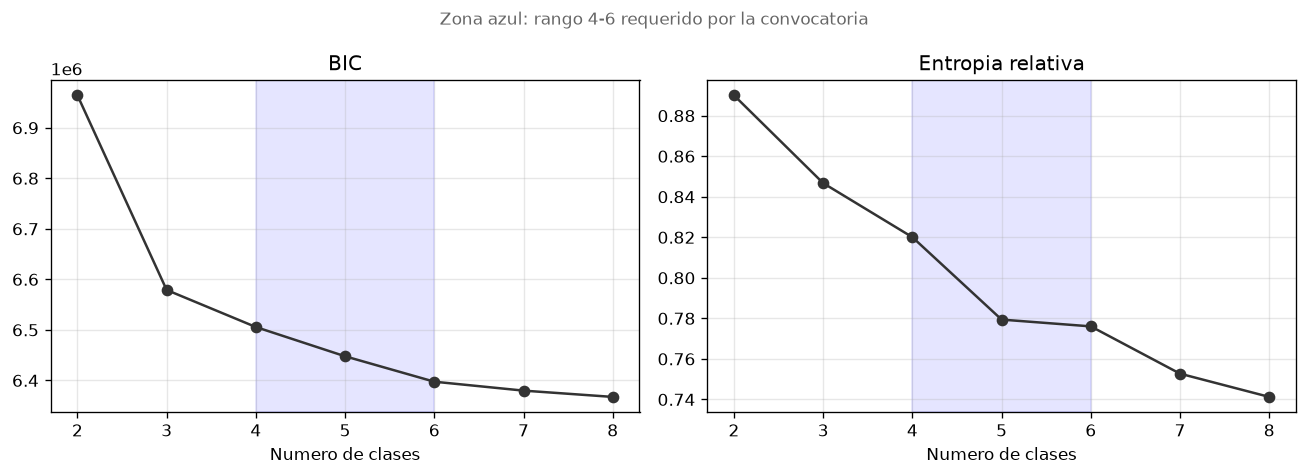

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(df_k["K"], df_k["BIC"], "o-", color="#333")
ax1.set_title("BIC")
ax2.plot(df_k["K"], df_k["entropia"], "o-", color="#333")
ax2.set_title("Entropia relativa")
for ax in (ax1, ax2):
    ax.axvspan(K_VALIDO.start, K_VALIDO.stop - 1, alpha=0.1, color="blue")
    ax.set_xlabel("Numero de clases")
    ax.grid(alpha=0.3)
plt.suptitle("Zona azul: rango 4-6 requerido por la convocatoria", fontsize=10, color="#666")
plt.tight_layout()
plt.show()

### 5.3 Elección de k

Si `K_ELEGIDO` es `None`: menor BIC dentro de 4-6 entre los modelos cuya clase más chica tiene al
menos 5% de las personas.

In [9]:
if K_ELEGIDO is None:
    cand = df_k[df_k["K"].isin(K_VALIDO) & (df_k["pct_min"] >= MIN_PCT_CLASE)]
    cand = cand if len(cand) else df_k[df_k["K"].isin(K_VALIDO)]
    K_ELEGIDO = int(cand.loc[cand["BIC"].idxmin(), "K"])
print(f"K elegido: {K_ELEGIDO}")

K elegido: 6


## 6. Clases

### 6.1 Perfil de respuesta

Las clases se ordenan por su categoria esperada promedio (0 = la de menor participación relativa).
Cada celda del mapa de calor es la probabilidad de que una celda de esa clase este en el tercil
alto (izquierda) o bajo (derecha) en cada elección.

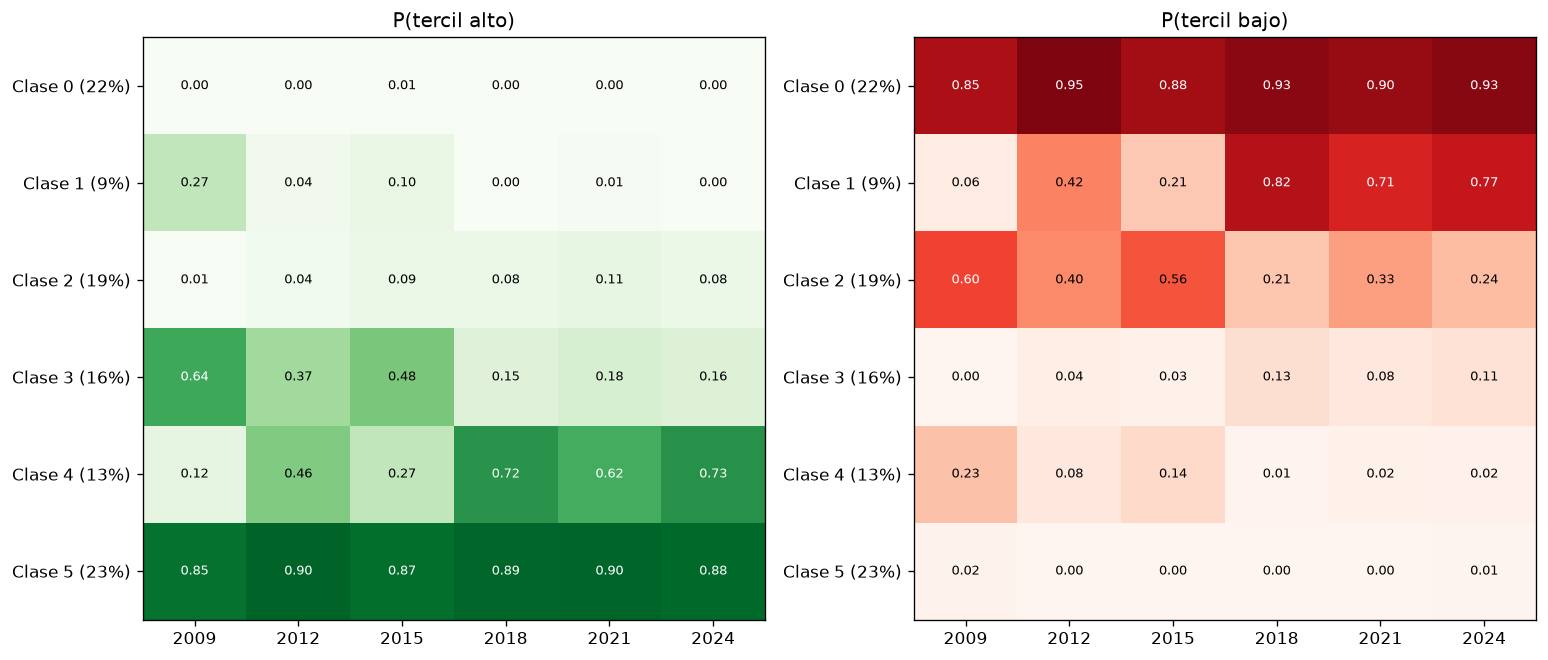

In [10]:
m = modelos[K_ELEGIDO]
orden = np.argsort((m["theta"] * np.arange(C)).sum(axis=2).mean(axis=1))
pi, theta, resp = m["pi"][orden], m["theta"][orden], m["resp"][:, orden]
nombres_clase = [f"Clase {k} ({pi[k] * 100:.0f}%)" for k in range(K_ELEGIDO)]

fig, axes = plt.subplots(1, 2, figsize=(13, 0.6 * K_ELEGIDO + 2))
for ax, c, titulo, cmap in [(axes[0], C - 1, "P(tercil alto)", "Greens"),
                            (axes[1], 0, "P(tercil bajo)", "Reds")]:
    datos = theta[:, :, c]
    ax.imshow(datos, cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(J), [c[1:] if c in ELECCIONES else "PJ2025" for c in INDICADORES])
    ax.set_yticks(range(K_ELEGIDO), nombres_clase)
    for k in range(K_ELEGIDO):
        for j in range(J):
            ax.text(j, k, f"{datos[k, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if datos[k, j] > 0.6 else "black")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### 6.2 Asignación de celdas

Cada celda recibe la clase más probable de su patrón. `prob_clase` es esa probabilidad; si es menor
a 0.8, la celda es ambigua entre clases.

In [11]:
clase_pat = resp.argmax(axis=1)
celdas["clase"] = clase_pat[inv]
celdas["prob_clase"] = resp.max(axis=1)[inv]
celdas["asignacion_clara"] = (celdas["prob_clase"] >= UMBRAL_CLARA).astype(float)

clara = np.average(celdas["asignacion_clara"], weights=w) * 100
print(f"Personas con asignacion clara (prob >= {UMBRAL_CLARA}): {clara:.1f}%")

Personas con asignacion clara (prob >= 0.8): 69.0%


### 6.3 Caracterización

Resumen ponderado por clase con las tasas reales (no los terciles): nivel, brecha, tendencia,
PJ 2025, composición y porcentaje de personas con asignación clara.

In [12]:
def media_ponderada(df, col, por):
    grupos = [df[c] for c in por]
    wx = (df[col] * df["peso"]).groupby(grupos).sum()
    return wx / df["peso"].where(df[col].notna()).groupby(grupos).sum()


def dominante(df, por, col):
    t = df.groupby(por + [col])["peso"].sum()
    return t.groupby(level=por).idxmax().map(lambda x: x[-1])


def resumen(df, por):
    personas = df.groupby(por)["peso"].sum()
    out = pd.DataFrame({"personas": personas, "pct_pob": personas / df["peso"].sum() * 100})
    cols = ["promedio", "brecha_pres", "tendencia", "P_PJ2025", "MUJER", "RURAL_MIXTA",
            "asignacion_clara"]
    for col in cols:
        out[col] = media_ponderada(df, col, por)
    out[["MUJER", "RURAL_MIXTA", "asignacion_clara"]] *= 100
    out["edad_dominante"] = dominante(df, por, "GRUPO_EDAD")
    out["region_dominante"] = dominante(df, por, "REGION")
    return out.round(1)


resumen(celdas, ["clase"])

,personas,pct_pob,promedio,brecha_pres,tendencia,P_PJ2025,MUJER,RURAL_MIXTA,asignacion_clara,edad_dominante,region_dominante
clase,,,,,,,,,,,
0,15253119,21.4,37.3,14.3,1.1,11.1,25.4,26.7,92.3,30-39,Centro
1,5934456,8.3,48.5,7.6,-1.6,10.0,43.5,36.2,44.3,30-39,Occidente
2,13265429,18.6,50.5,18.4,3.0,14.0,52.6,23.7,59.1,30-39,Centro
3,11639641,16.3,60.3,9.3,-0.1,11.9,56.7,32.5,56.9,40-49,Centro
4,8413205,11.8,62.0,19.5,4.5,15.2,68.2,27.3,51.3,40-49,Centro
5,16697727,23.5,72.8,10.6,1.8,15.0,68.9,37.6,81.8,50-59,Centro


### 6.4 Trayectorias

Participación ponderada real por clase en cada elección.

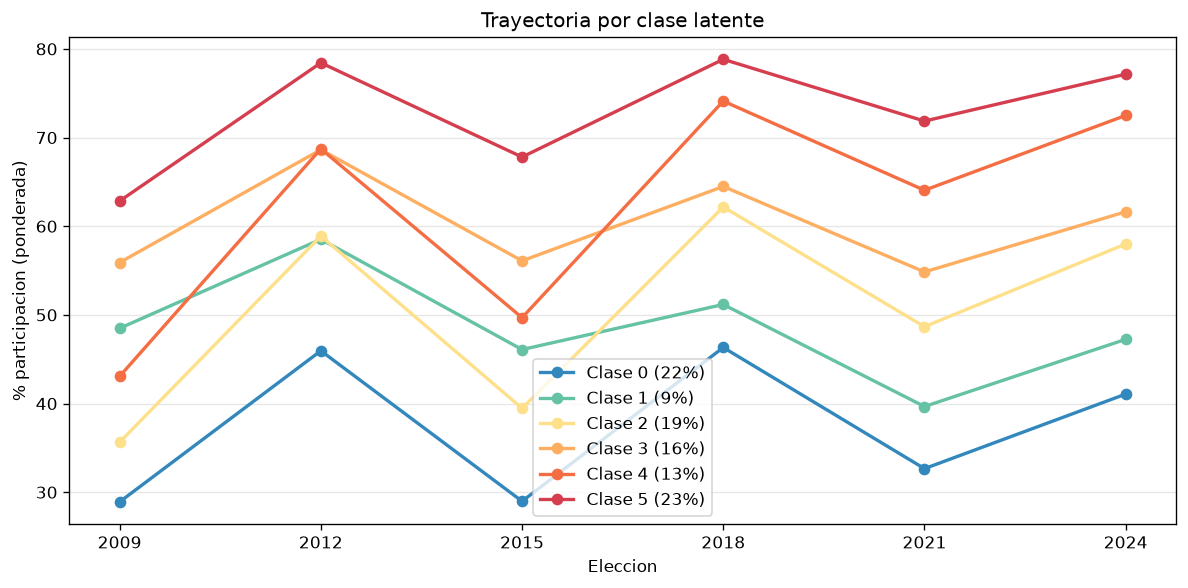

In [13]:
anos = [2009, 2012, 2015, 2018, 2021, 2024]
tray = pd.DataFrame({e: media_ponderada(celdas, e, ["clase"]) for e in ELECCIONES})

fig, ax = plt.subplots(figsize=(10, 5))
for k, fila in tray.iterrows():
    ax.plot(anos, fila.to_numpy(), "o-", color=COLORES_PERFIL[k], linewidth=2, label=nombres_clase[k])
ax.set_xticks(anos)
ax.set_xlabel("Eleccion")
ax.set_ylabel("% participacion (ponderada)")
ax.set_title("Trayectoria por clase latente")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Composición por edad

Distribución de edad dentro de cada clase (% de personas).

In [14]:
edad = celdas.groupby(["clase", "GRUPO_EDAD"])["peso"].sum().unstack(fill_value=0)[ETIQUETAS_EDAD]
(edad.div(edad.sum(axis=1), axis=0) * 100).round(1)

GRUPO_EDAD,18-24,25-29,30-39,40-49,50-59,60-69,70-79,80+
clase,,,,,,,,
0,29.0,27.2,30.9,8.1,2.1,0.5,0.4,1.6
1,20.2,14.0,28.4,21.6,9.7,3.0,2.0,0.9
2,21.9,14.1,30.4,18.5,8.1,3.0,2.3,1.6
3,10.1,5.5,18.0,26.3,23.9,11.3,4.6,0.3
4,8.9,4.3,18.1,25.5,21.8,13.4,7.6,0.4
5,3.5,2.1,9.2,19.8,28.7,27.4,9.3,0.1


## 7. Estabilidad y comparación

### 7.1 Bootstrap

Bootstrap de Poisson sobre las celdas (peso x Poisson(1)), se reagregan los patrones y se reajusta
el modelo con el mismo k. ARI de la clase asignada contra la original en la muestra eval.

In [15]:
aris = []
for b in range(N_BOOT):
    w_b = w * np.random.default_rng(1000 + b).poisson(1.0, size=len(w))
    f_b = np.bincount(inv, weights=w_b, minlength=len(patrones))
    f_b = f_b / f_b.sum() * n_celdas
    m_b = mejor_lca(K_ELEGIDO, f_b, seed=1000 + b * N_INIT, n_init=10)
    clase_b = m_b["resp"].argmax(axis=1)[inv]
    aris.append(adjusted_rand_score(celdas["clase"].to_numpy()[idx_eval], clase_b[idx_eval]))
print(f"ARI medio: {np.mean(aris):.3f}  minimo: {np.min(aris):.3f}")

ARI medio: 0.982  minimo: 0.950


### 7.2 Comparación con modelos previos

ARI contra los modelos guardados por los notebooks 05-07 (solo los archivos que existan).

In [16]:
llaves = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
comparar = {
    "celdas_perfiles_candidatos.parquet": ["base_04", "candidato_1"],
    "celdas_perfiles_candidatos_forma.parquet": ["forma_1"],
    "celdas_jerarquia.parquet": ["perfil"],
}
for archivo, cols in comparar.items():
    ruta = DIR_PREPROCESSED / archivo
    if not ruta.exists():
        print(f"No existe {archivo}")
        continue
    otro = celdas[llaves].merge(pd.read_parquet(ruta, columns=llaves + cols), on=llaves, how="left")
    for col in cols:
        etiquetas = otro[col].fillna(-1).astype(int).to_numpy()[idx_eval]
        ari = adjusted_rand_score(celdas["clase"].to_numpy()[idx_eval], etiquetas)
        print(f"ARI vs {archivo} [{col}]: {ari:.3f}")

ARI vs celdas_perfiles_candidatos.parquet [base_04]: 0.315
ARI vs celdas_perfiles_candidatos.parquet [candidato_1]: 0.379
ARI vs celdas_perfiles_candidatos_forma.parquet [forma_1]: 0.081


ARI vs celdas_jerarquia.parquet [perfil]: 0.258


## 8. Exportacion

In [17]:
clases = resumen(celdas, ["clase"])
for j, c in enumerate(INDICADORES):
    clases[f"p_alta_{c}"] = pd.Series(theta[:, j, C - 1], index=range(K_ELEGIDO)).round(3)

salidas = {
    "celdas_clases_latentes.parquet": celdas[llaves + ["peso", "clase", "prob_clase"]],
    "lca_seleccion_k.csv": df_k,
    "lca_clases.csv": clases,
}
for nombre, df in salidas.items():
    ruta = DIR_PREPROCESSED / nombre
    if nombre.endswith(".parquet"):
        df.to_parquet(ruta, index=False)
    else:
        df.to_csv(ruta, index=nombre == "lca_clases.csv")
    print(f"{nombre}: {ruta.stat().st_size / 1024:.0f} KB")

celdas_clases_latentes.parquet: 2318 KB
lca_seleccion_k.csv: 1 KB
lca_clases.csv: 1 KB
